# 02 · Geography: where did IT work grow or shrink after 2019?

**Question:** across US metro areas, how did IT services grow between 2019 and 2024, and what predicts it?
**Data:** `data/processed/metro_panel.csv` (run `python build_metro_panel.py`). IT here means **NAICS 5415 (computer systems design and related services)**: consulting and contract IT, *not* software publishers or big-tech product companies.

**Two outcomes, because the data has a gap:**
- **A. IT employment** (jobs). Better measure, but the BLS withholds it for some metros (including Chicago, Houston, Atlanta).
- **B. IT establishments** (firms/sites). Never withheld, so it covers (almost) every metro, but counts places, not people.

All growth rates below are **log points** (100 × ln(2024/2019)), which tames outliers from small metros. Coefficients are per **+1 standard deviation** of a predictor.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "build_master.py").exists())
import sys; sys.path.insert(0, str(ROOT))
from analysis import metro_models as mm

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 12, "axes.titleweight": "bold"})
def save(fig, name): fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

p = mm.prepare(pd.read_csv(ROOT / "data" / "processed" / "metro_panel.csv", dtype={"cbsa_code": str}))
p["metro"] = p["metro_name"].fillna(p["cbsa_code"]).str.replace(r" Metro Area", "", regex=True)
allm = p["emp_total_2019"]; big = p.loc[allm.nlargest(25).index]
cov = pd.DataFrame({
    "metros": [int(p.usable.sum()), int(p.usable_estab.sum())],
    "share of all private jobs": [allm[p.usable].sum() / allm.sum(), allm[p.usable_estab].sum() / allm.sum()],
    "of the 25 biggest": [int(big.usable.sum()), int(big.usable_estab.sum())],
    "median growth 2019-24 (%)": [p.loc[p.usable, "it_growth_pct"].median(), p.loc[p.usable_estab, "estab_growth_pct"].median()],
}, index=["A. IT employment", "B. IT establishments"])
cov.style.format({"share of all private jobs": "{:.0%}", "median growth 2019-24 (%)": "{:.1f}"})

,metros,share of all private jobs,of the 25 biggest,median growth 2019-24 (%)
A. IT employment,258,70%,20,12.6
B. IT establishments,372,99%,25,44.5


## 1 · The biggest metros: do the two outcomes agree?
Each row is one of the 25 largest metros (by total private employment). Blank blue dot = IT employment withheld by the BLS.

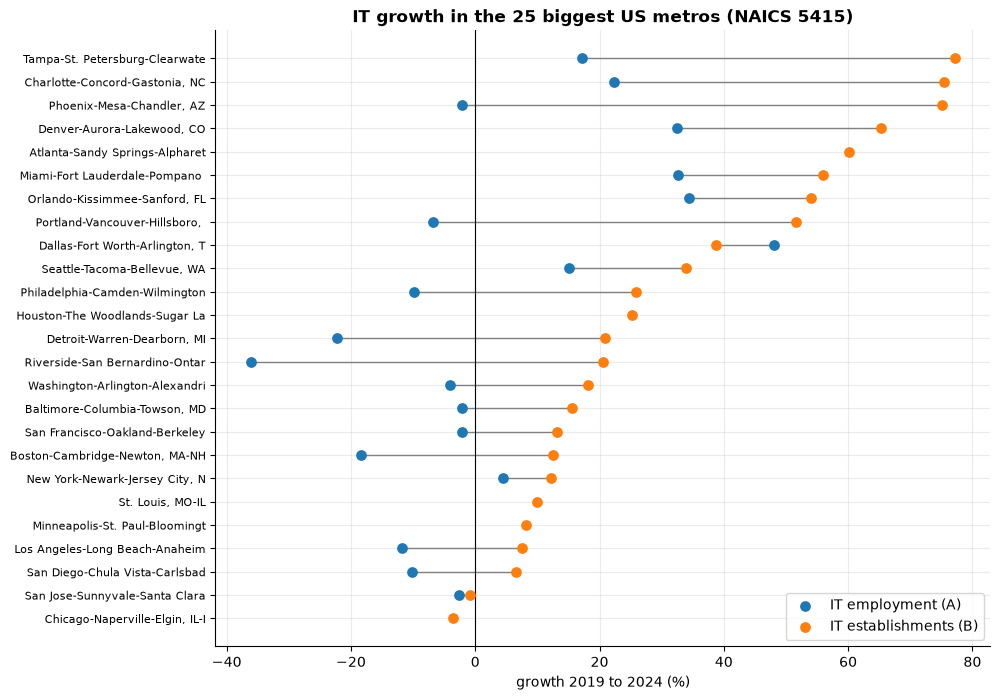

In [2]:
b = big.sort_values("estab_growth_pct").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 8))
for i, r in b.iterrows():
    if pd.notna(r.it_growth_pct): ax.plot([r.it_growth_pct, r.estab_growth_pct], [i, i], color="grey", lw=1)
ax.scatter(b.it_growth_pct, b.index, color="tab:blue", s=45, label="IT employment (A)", zorder=3)
ax.scatter(b.estab_growth_pct, b.index, color="tab:orange", s=45, label="IT establishments (B)", zorder=3)
ax.set_yticks(b.index); ax.set_yticklabels(b.metro.str.slice(0, 30), fontsize=8)
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("growth 2019 to 2024 (%)"); ax.legend(loc="lower right")
ax.set_title("IT growth in the 25 biggest US metros (NAICS 5415)")
save(fig, "10_big_metros_two_outcomes"); plt.show()

## 2 · The size effect: small metros and big IT establishments
Small bases make growth noisy, and metros whose IT establishments were large in 2019 grew less. Dots = metros, line = median by bin.

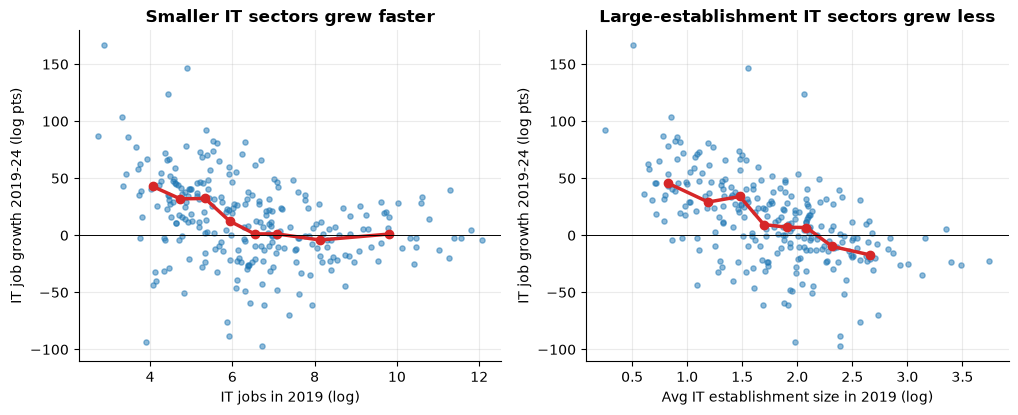

Correlation of IT job growth with: {'log_it_emp': np.float64(-0.34), 'log_estab_size': np.float64(-0.55)}


In [3]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3))
a = p[p.usable]
for ax, x, xl in [(axs[0], "log_it_emp", "IT jobs in 2019 (log)"), (axs[1], "log_estab_size", "Avg IT establishment size in 2019 (log)")]:
    ax.scatter(a[x], a["yA"], s=14, alpha=0.5)
    g = a.assign(bin=pd.qcut(a[x], 8)).groupby("bin", observed=True).agg(x=(x, "median"), y=("yA", "median"))
    ax.plot(g.x, g.y, color="tab:red", lw=2.5, marker="o"); ax.axhline(0, color="black", lw=0.7)
    ax.set_xlabel(xl); ax.set_ylabel("IT job growth 2019-24 (log pts)")
axs[0].set_title("Smaller IT sectors grew faster"); axs[1].set_title("Large-establishment IT sectors grew less")
save(fig, "11_size_effects"); plt.show()
print("Correlation of IT job growth with:", {k: round(a[["yA", k]].corr().iloc[0, 1], 2) for k in ["log_it_emp", "log_estab_size"]})

## 3 · What predicts growth? Robust regression with cross-validation
Bars are coefficients with 95% intervals (robust standard errors). **R²** is in-sample; **CV R²** is on held-out metros (the honest number; negative would mean no better than guessing the mean).

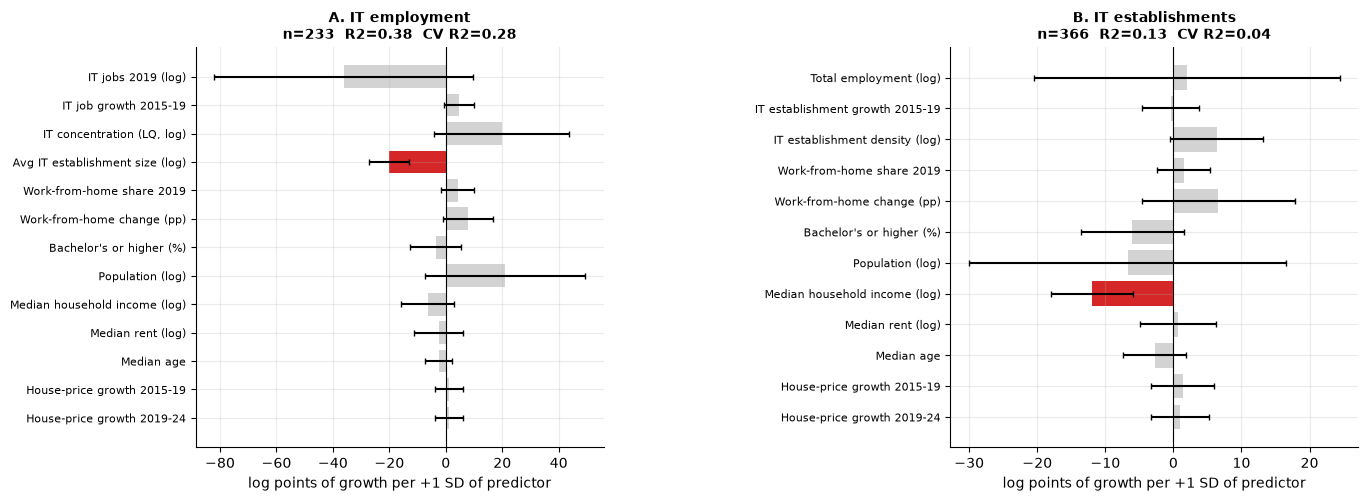

A -> significant at 95%: ['Avg IT establishment size (log)']
B -> significant at 95%: ['Median household income (log)']


In [4]:
res = {w: mm.run(p, w) for w in ("A", "B")}
fig, axs = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"wspace": 0.85})
for ax, w, title in [(axs[0], "A", "A. IT employment"), (axs[1], "B", "B. IT establishments")]:
    r = res[w]; t = r["table"].iloc[::-1]
    sig = (t.ci_lo > 0) | (t.ci_hi < 0)
    ax.barh([mm.LABELS[i] for i in t.index], t.coef, xerr=[t.coef - t.ci_lo, t.ci_hi - t.coef],
            color=["tab:red" if s else "lightgrey" for s in sig], ecolor="black", capsize=2)
    ax.axvline(0, color="black", lw=0.8); ax.tick_params(axis="y", labelsize=8)
    ax.set_title(f"{title}\nn={r['n']}  R2={r['r2']:.2f}  CV R2={r['cv_mean']:.2f}", fontsize=10)
    ax.set_xlabel("log points of growth per +1 SD of predictor")
save(fig, "12_coefficients"); plt.show()
for w in res: print(w, "-> significant at 95%:", [mm.LABELS[i] for i, s in ((i, (res[w]['table'].loc[i,'ci_lo'] > 0) or (res[w]['table'].loc[i,'ci_hi'] < 0)) for i in res[w]['table'].index) if s])

## 4 · Work from home: did bigger remote-work jumps coincide with weaker IT growth?
Work-from-home share change 2015-19 vs 2020-24 (Census ACS 5-year), against each outcome.

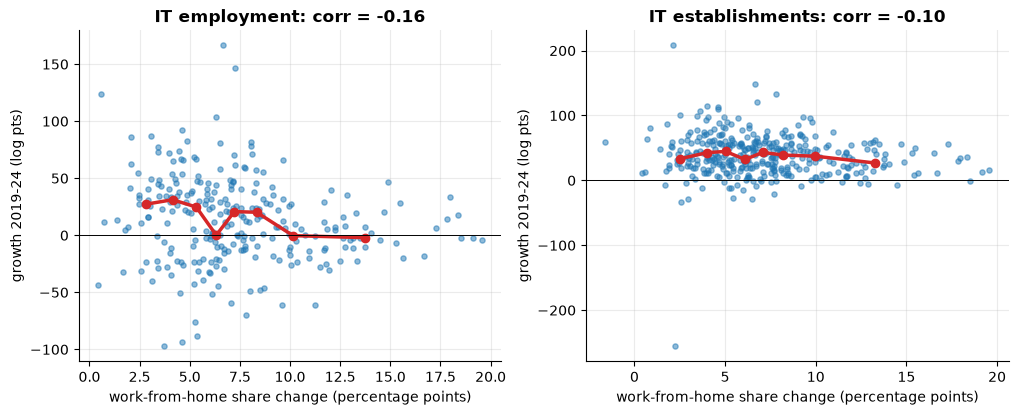

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, w, y, title in [(axs[0], "A", "yA", "IT employment"), (axs[1], "B", "yB", "IT establishments")]:
    d = p[p[mm.SUBSET_COL[w]]].dropna(subset=["wfh_change_pp", y])
    ax.scatter(d.wfh_change_pp, d[y], s=14, alpha=0.5)
    g = d.assign(bin=pd.qcut(d.wfh_change_pp, 8)).groupby("bin", observed=True).agg(x=("wfh_change_pp", "median"), y=(y, "median"))
    ax.plot(g.x, g.y, color="tab:red", lw=2.5, marker="o"); ax.axhline(0, color="black", lw=0.7)
    ax.set_xlabel("work-from-home share change (percentage points)"); ax.set_ylabel("growth 2019-24 (log pts)")
    ax.set_title(f"{title}: corr = {d[['wfh_change_pp', y]].corr().iloc[0, 1]:.2f}")
save(fig, "13_wfh_vs_growth"); plt.show()

## What this shows, and what it cannot

**Reasonably solid**
- Where the data exists, IT *employment* growth is partly predictable: roughly a quarter to a third of the variation in held-out metros.
- The one predictor that survives robust standard errors is **average IT establishment size**: metros whose IT sector was concentrated in larger establishments in 2019 grew less.
- The Sun Belt and Mountain metros (Dallas, Denver, Miami, Orlando, Tampa, Charlotte) grew on **both** outcomes; several older hubs (Boston, Detroit, Los Angeles, Philadelphia, San Diego) lost jobs while still adding establishments.

**Weak or unproven**
- IT *establishment* growth is barely predictable (CV R² near zero). The one robust predictor is **median household income**: higher-income metros added fewer IT establishments. Establishment counts are noisy and include many tiny establishments.
- Several size-related predictors (IT jobs, population, IT concentration) move together, so their individual bars in section 3 are wide. Read them as a group, not one by one.
- Work-from-home change shows no strong link to either outcome once other factors are controlled. This does **not** show remote work had no effect: IT workers adopt remote work more readily, so the arrow could run either way.

**Cannot say**
- IT = NAICS 5415 only. Software publishers and big-tech product companies are not in this measure.
- Five of the 25 biggest metros (Chicago, Houston, Atlanta, Minneapolis, St. Louis) have no IT employment figure; they appear only in outcome B.
- These are associations across metros, not causes.